In [1]:
### standard libraries
import numpy as np
import matplotlib.pyplot as plt

### my modules
from fast_volume_align_ot import utils, plots

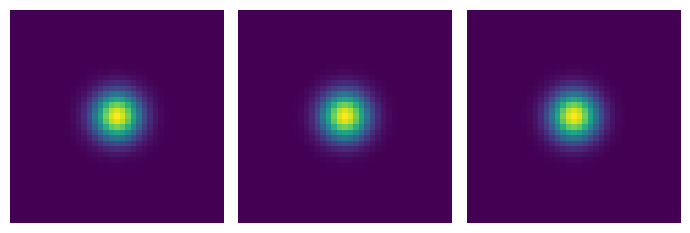

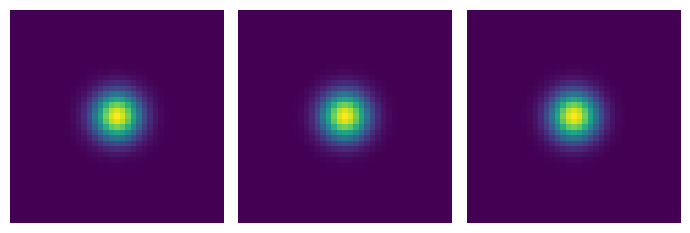

In [9]:
### single centered Gaussian

### inputs
L = 39  # the volume size
d = 3
sigma = 3

vol = utils.generate_centered_gaussian(L, d, sigma)

plots.orthogonal_2D_projection_plot(vol)
plots.orthogonal_2D_slice_plot(vol)

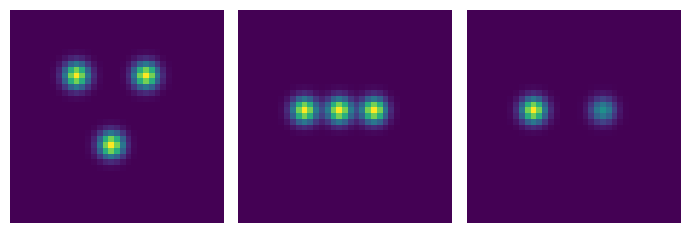

In [55]:
### triple Gaussian
### L needs to be in (6n + 1) to be equal spaced gaussians
### e.g. 25,  31,  37,  43,  49,  55,  61,  67,  73, 79,  85

### inputs
L = 37  # the volume size
d = 3
sigma = 1.5
vol = np.zeros((L,L,L))

p1 = L//2
p2 = L//3
vol[p1, p2, p2] = 1
vol[p1, p2, 2*p2] = 1
vol[p1, 2*p2, p1] = 1

g = utils.generate_centered_gaussian(L, d, sigma)
vol = utils.signal_convolution(vol, g)
# vol = vol.astype(np.complex128)

plots.orthogonal_2D_projection_plot(vol)
# plots.orthogonal_2D_slice_plot(vol)

In [56]:
def generate_3d_triangle_gaussian_shape(L, sigma):
    """
    input: L = integer size of grid
    notes: L needs to be in {6n + 1}, e.g., 31,  37,  43,  49,  55,  61,  67,  73, 79,  85
    output: a 3D voxel grid with 3 Gaussians in following shape
    (x-projection to zy-plane)
     -------------
    |             |
    |   x     x   |
    |             |
    |      x      |
    |             |
     -------------
    TODO: define grid on [-1,1], then interpolate
    """

    vol = np.zeros((L,L,L))
    
    p1 = L//2
    p2 = L//3
    vol[p1, p2, p2] = 1
    vol[p1, p2, 2*p2] = 1
    vol[p1, 2*p2, p1] = 1
    
    g = utils.generate_centered_gaussian(L, d=3, sigma)
    vol = utils.signal_convolution(vol, g)

    return vol

In [71]:
z = generate_3d_triangle_gaussian_shape(37, 1.5)

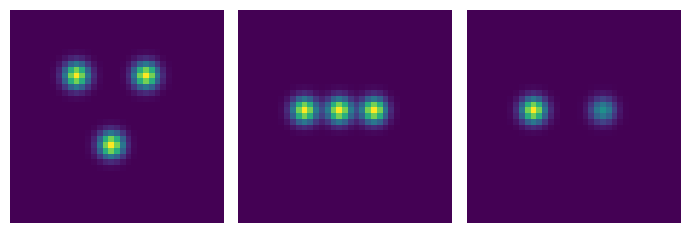

In [72]:
plots.orthogonal_2D_projection_plot(z)

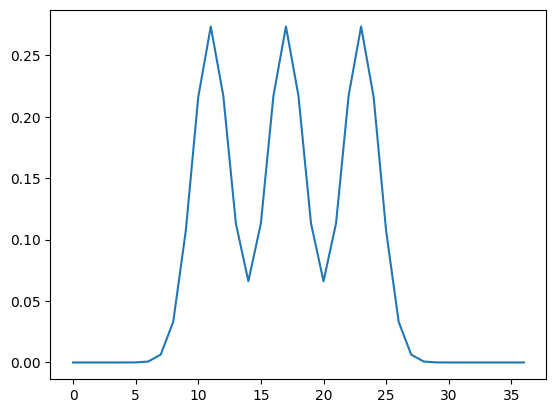

In [73]:
plt.plot(z.sum(axis=(0,1)))